In [7]:
import pandas as pd

In [8]:
df = pd.read_csv("Iris.csv")

In [9]:
num_df = df.select_dtypes(include=['number'])

In [10]:
dispersion = pd.DataFrame({
      "Range": num_df.max() - num_df.min(),
          "Variance": num_df.var(),
              "Standard Deviation": num_df.std(),
                  "Interquartile Range (IQR)": num_df.quantile(0.75) - num_df.quantile(0.25),
                      "Coefficient of Variation (%)": (num_df.std() / num_df.mean()) * 100
})

In [11]:
print(dispersion)

               Range     Variance  Standard Deviation  \
Id             149.0  1887.500000           43.445368   
SepalLengthCm    3.6     0.685694            0.828066   
SepalWidthCm     2.4     0.188004            0.433594   
PetalLengthCm    5.9     3.113179            1.764420   
PetalWidthCm     2.4     0.582414            0.763161   

               Interquartile Range (IQR)  Coefficient of Variation (%)  
Id                                  74.5                     57.543534  
SepalLengthCm                        1.3                     14.171126  
SepalWidthCm                         0.5                     14.197587  
PetalLengthCm                        3.5                     46.942721  
PetalWidthCm                         1.5                     63.667470  


In [12]:
df['Row_Range'] = num_df.max(axis=1) - num_df.min(axis=1)
df['Row_Variance'] = num_df.var(axis=1)
df['Row_Std_Deviation'] = num_df.std(axis=1)

print(df.head())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   Row_Range  Row_Variance  Row_Std_Deviation  
0        4.9         4.043           2.010721  
1        4.7         3.140           1.772005  
2        4.5         3.077           1.754138  
3        4.4         3.287           1.813009  
4        4.8         4.688           2.165179  


In [13]:
dispersion.to_excel("iris_dispersion.xlsx", index=False)

In [14]:
print("iris_dispersion.xlsx")

iris_dispersion.xlsx


In [15]:
print(df.columns)

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species', 'Row_Range', 'Row_Variance', 'Row_Std_Deviation'],
      dtype='object')


In [16]:
print(df.dtypes)

Id                     int64
SepalLengthCm        float64
SepalWidthCm         float64
PetalLengthCm        float64
PetalWidthCm         float64
Species               object
Row_Range            float64
Row_Variance         float64
Row_Std_Deviation    float64
dtype: object


In [17]:
print(df.shape)

(150, 9)


In [18]:
print(df.describe())

               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
count  150.000000     150.000000    150.000000     150.000000    150.000000   
mean    75.500000       5.843333      3.054000       3.758667      1.198667   
std     43.445368       0.828066      0.433594       1.764420      0.763161   
min      1.000000       4.300000      2.000000       1.000000      0.100000   
25%     38.250000       5.100000      2.800000       1.600000      0.300000   
50%     75.500000       5.800000      3.000000       4.350000      1.300000   
75%    112.750000       6.400000      3.300000       5.100000      1.800000   
max    150.000000       7.900000      4.400000       6.900000      2.500000   

        Row_Range  Row_Variance  Row_Std_Deviation  
count  150.000000    150.000000         150.000000  
mean    74.363333   1404.738807          32.364138  
std     42.656050   1276.990669          18.965743  
min      4.400000      3.077000           1.754138  
25%     38.125000    26

In [19]:
print(df.isnull().sum())

Id                   0
SepalLengthCm        0
SepalWidthCm         0
PetalLengthCm        0
PetalWidthCm         0
Species              0
Row_Range            0
Row_Variance         0
Row_Std_Deviation    0
dtype: int64


In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
iris_numeric=df.select_dtypes(include=["float64","int64"])
corr_matrix=iris_numeric.corr()
print("correlation Matrix:")
print(corr_matrix)

correlation Matrix:
                         Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  \
Id                 1.000000       0.716676     -0.397729       0.882747   
SepalLengthCm      0.716676       1.000000     -0.109369       0.871754   
SepalWidthCm      -0.397729      -0.109369      1.000000      -0.420516   
PetalLengthCm      0.882747       0.871754     -0.420516       1.000000   
PetalWidthCm       0.899759       0.817954     -0.356544       0.962757   
Row_Range          0.999927       0.713694     -0.398003       0.879891   
Row_Variance       0.966042       0.669428     -0.291951       0.806762   
Row_Std_Deviation  0.999856       0.711212     -0.398745       0.878898   

                   PetalWidthCm  Row_Range  Row_Variance  Row_Std_Deviation  
Id                     0.899759   0.999927      0.966042           0.999856  
SepalLengthCm          0.817954   0.713694      0.669428           0.711212  
SepalWidthCm          -0.356544  -0.398003     -0.291951          -0.3

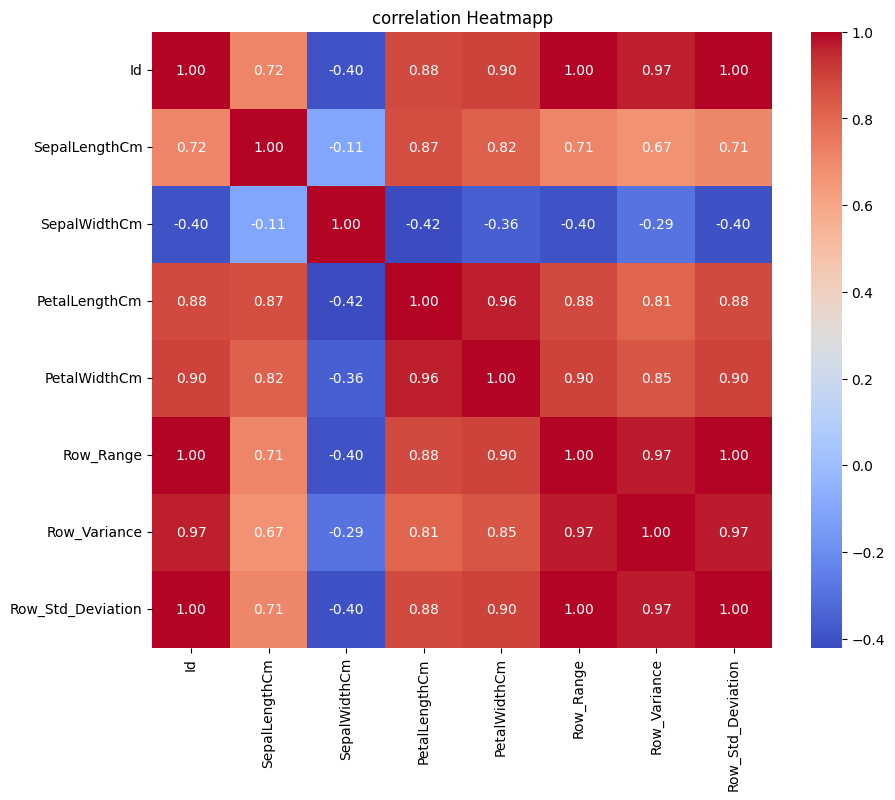

In [21]:
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt=".2f")
plt.title("correlation Heatmapp")
plt.show()

In [22]:
print("Descriptive statistics:")
print(iris_numeric.describe())
print("/nVariance:")
print(iris_numeric.var())
print("\nstandard Deviation:")
print(iris_numeric.std())

Descriptive statistics:
               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
count  150.000000     150.000000    150.000000     150.000000    150.000000   
mean    75.500000       5.843333      3.054000       3.758667      1.198667   
std     43.445368       0.828066      0.433594       1.764420      0.763161   
min      1.000000       4.300000      2.000000       1.000000      0.100000   
25%     38.250000       5.100000      2.800000       1.600000      0.300000   
50%     75.500000       5.800000      3.000000       4.350000      1.300000   
75%    112.750000       6.400000      3.300000       5.100000      1.800000   
max    150.000000       7.900000      4.400000       6.900000      2.500000   

        Row_Range  Row_Variance  Row_Std_Deviation  
count  150.000000    150.000000         150.000000  
mean    74.363333   1404.738807          32.364138  
std     42.656050   1276.990669          18.965743  
min      4.400000      3.077000           1.754138  

In [23]:
cv=(iris_numeric.std()/iris_numeric.mean())
print("\ncoefficient of varition:")
print(cv)


coefficient of varition:
Id                   0.575435
SepalLengthCm        0.141711
SepalWidthCm         0.141976
PetalLengthCm        0.469427
PetalWidthCm         0.636675
Row_Range            0.573617
Row_Variance         0.909059
Row_Std_Deviation    0.586011
dtype: float64


In [24]:
maximum=iris_numeric.max()
minimum=iris_numeric.min()
range=maximum-minimum
print("\ncoefficient of Range:")
print(range)


coefficient of Range:
Id                    149.000000
SepalLengthCm           3.600000
SepalWidthCm            2.400000
PetalLengthCm           5.900000
PetalWidthCm            2.400000
Row_Range             143.800000
Row_Variance         4265.706000
Row_Std_Deviation      63.581786
dtype: float64


In [25]:
Q1=iris_numeric.quantile(0.25)
Q3=iris_numeric.quantile(0.75)
coefficient_of_quartile_deviation=(Q3-Q1)/(Q3+Q1)
print("\ncofficient of Quartile Deviatiom:")
print(coefficient_of_quartile_deviation)


cofficient of Quartile Deviatiom:
Id                   0.493377
SepalLengthCm        0.113043
SepalWidthCm         0.081967
PetalLengthCm        0.522388
PetalWidthCm         0.714286
Row_Range            0.487653
Row_Variance         0.800738
Row_Std_Deviation    0.500802
dtype: float64


In [26]:
mean=iris_numeric.mean()
mean_deviation=abs(iris_numeric-mean)
coefficient_of_mean_devition=mean_deviation.mean()/mean
print("\ncoefficient of mean Deviation:")
print(coefficient_of_mean_devition)


coefficient of mean Deviation:
Id                   0.496689
SepalLengthCm        0.117665
SepalWidthCm         0.109068
PetalLengthCm        0.415552
PetalWidthCm         0.549722
Row_Range            0.495540
Row_Variance         0.779282
Row_Std_Deviation    0.506798
dtype: float64
